TODO:

- [x] download the data
- [ ] read the hugging face tutorials
- [ ] reproduce the results of the tutorial
- [ ] create a baseline model?

In [1]:
# Make sure you called the prepare_dataset.py script before running this one

from datasets import load_dataset
dataset = load_dataset("imagefolder", data_dir="dl_action_dataset")

Resolving data files:   0%|          | 0/2352 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/503 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/509 [00:00<?, ?it/s]

Found cached dataset imagefolder (/home/enerd/.cache/huggingface/datasets/imagefolder/default-43af9a33c931872c/0.0.0/37fbb85cc714a338bea574ac6c7d0b5be5aff46c1862c1989b20e0771199e93f)


  0%|          | 0/3 [00:00<?, ?it/s]

In [2]:
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 2352
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 503
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 509
    })
})

In [3]:
print("Available classes:", *dataset["train"].features["label"].names)

Available classes: cut pour slide stir


Loading cached processed dataset at /home/enerd/.cache/huggingface/datasets/imagefolder/default-43af9a33c931872c/0.0.0/37fbb85cc714a338bea574ac6c7d0b5be5aff46c1862c1989b20e0771199e93f/cache-a8abffca9e62f59d.arrow


Loading cached processed dataset at /home/enerd/.cache/huggingface/datasets/imagefolder/default-43af9a33c931872c/0.0.0/37fbb85cc714a338bea574ac6c7d0b5be5aff46c1862c1989b20e0771199e93f/cache-942d4d0218bbec3d.arrow
Loading cached processed dataset at /home/enerd/.cache/huggingface/datasets/imagefolder/default-43af9a33c931872c/0.0.0/37fbb85cc714a338bea574ac6c7d0b5be5aff46c1862c1989b20e0771199e93f/cache-ba59ebc06088caae.arrow
Loading cached processed dataset at /home/enerd/.cache/huggingface/datasets/imagefolder/default-43af9a33c931872c/0.0.0/37fbb85cc714a338bea574ac6c7d0b5be5aff46c1862c1989b20e0771199e93f/cache-a173abd1324cb1b0.arrow


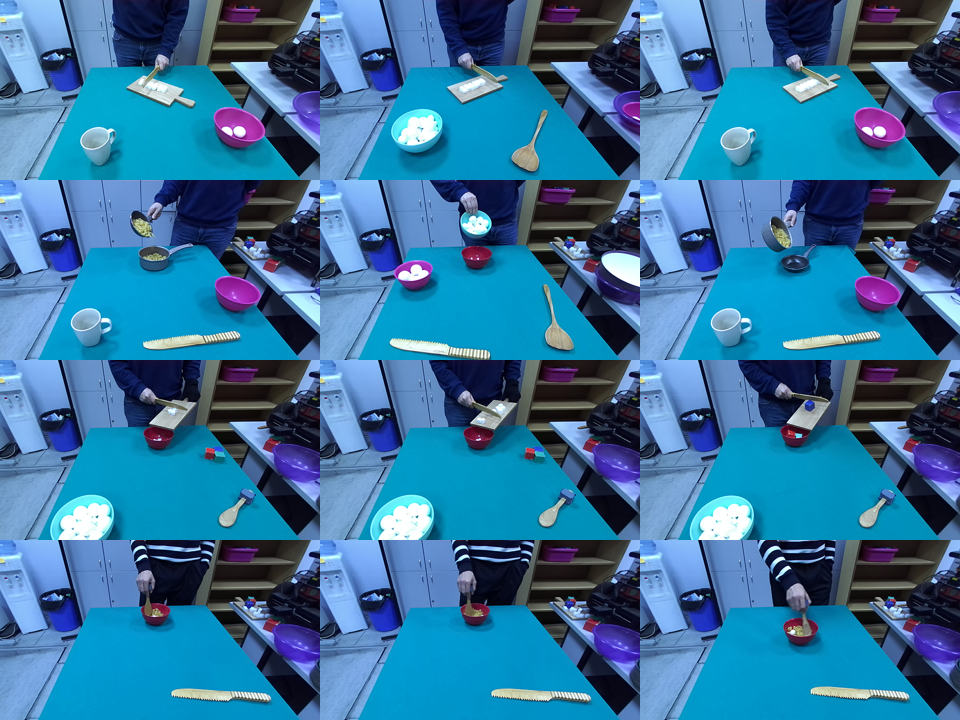

In [5]:
from PIL import ImageDraw, Image
import numpy as np

# Borrowed and modified from https://huggingface.co/blog/fine-tune-vit 
def show_examples(ds, examples_per_class):

    h, w, _ = np.array(dataset['train'][10]["image"]).shape
    h, w = h // 2, w // 2
    size = (w, h)
    
    labels = ds['train'].features['label'].names
    grid = Image.new('RGB', size=(examples_per_class * w, len(labels) * h))
    draw = ImageDraw.Draw(grid)

    for label_id, label in enumerate(labels):

        # Filter the dataset by a single label, shuffle it, and grab a few samples
        ds_slice = ds['train'].filter(lambda ex: ex['label'] == label_id, ).shuffle().select(range(examples_per_class))

        # Plot this label's examples along a row
        for i, example in enumerate(ds_slice):
            image = example['image']
            idx = examples_per_class * label_id + i
            box = (idx % examples_per_class * w, idx // examples_per_class * h)
            grid.paste(image.resize(size), box=box)

    return grid

show_examples(dataset, examples_per_class=3)


In [6]:
labels = dataset["train"].features["label"].names
label2id, id2label = dict(), dict()
for i, label in enumerate(labels):
    label2id[label] = i
    id2label[i] = label

In [7]:
# The pretrained ViT model:
model_name = 'google/vit-base-patch16-224-in21k'


In [24]:
# Preprocess the images (just normalization)

from transformers import ViTImageProcessor # type: ignore


processor = ViTImageProcessor.from_pretrained(model_name)

def transform(example_batch):
    # Take a list of PIL images and turn them to pixel values
    inputs = processor([x for x in example_batch['image']], return_tensors='pt')

    # Don't forget to include the labels!
    inputs['label'] = example_batch['label']
    return inputs


# According to documentation, following code will transform the dataset in a lazy way
# (i.e. it will transform the dataset on the fly, when needed)
prepared_ds = dataset.with_transform(transform)

In [25]:
# processor

In [26]:
from datasets import load_metric

metric = load_metric("accuracy")
def compute_metrics(p):
    return metric.compute(predictions=np.argmax(p.predictions, axis=1), references=p.label_ids)

In [27]:
from transformers import ViTForImageClassification


model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

Some weights of the model checkpoint at google/vit-base-patch16-224-in21k were not used when initializing ViTForImageClassification: ['pooler.dense.weight', 'pooler.dense.bias']
- This IS expected if you are initializing ViTForImageClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTForImageClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [28]:
model

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0): ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_

In [29]:
from transformers import TrainingArguments # type:ignore

# About the args: https://huggingface.co/docs/transformers/main_classes/trainer#transformers.TrainingArguments
training_args = TrainingArguments(
  output_dir="./vit-ar",
  per_device_train_batch_size=32,
  evaluation_strategy="steps",
  num_train_epochs=14,
  save_steps=100,
  eval_steps=100,
  logging_steps=10,
  learning_rate=2e-4,
  save_total_limit=2,
  remove_unused_columns=False,
  push_to_hub=False,
  report_to='tensorboard',
  load_best_model_at_end=True,
)

In [34]:
import torch

def collate_fn(batch):
    return {
        'pixel_values': torch.stack([x['pixel_values'] for x in batch]),
        'labels': torch.tensor([x['label'] for x in batch])
    }

In [35]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    data_collator=collate_fn,
    compute_metrics=compute_metrics,
    train_dataset=prepared_ds["train"],
    eval_dataset=prepared_ds["validation"],
    tokenizer=processor,
)

In [36]:
train_results = trainer.train()
trainer.save_model()
trainer.log_metrics("train", train_results.metrics)
trainer.save_metrics("train", train_results.metrics)
trainer.save_state()

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:1                                                                                    │
│                                                                                                  │
│ ❱ 1 train_results = trainer.train()                                                              │
│   2 trainer.save_model()                                                                         │
│   3 trainer.log_metrics("train", train_results.metrics)                                          │
│   4 trainer.save_metrics("train", train_results.metrics)                                         │
│                                                                                                  │
│ /home/enerd/miniconda3/envs/torch/lib/python3.7/site-packages/transformers/trainer.py:1649 in    │
│ train                                                                                            │
│                                                                                                  │
│   1646 │   │   │   args=args,                                                                    │
│   1647 │   │   │   resume_from_checkpoint=resume_from_checkpoint,                                │
│   1648 │   │   │   trial=trial,                                                                  │
│ ❱ 1649 │   │   │   ignore_keys_for_eval=ignore_keys_for_eval,                                    │
│   1650 │   │   )                                                                                 │
│   1651 │                                                                                         │
│   1652 │   def _inner_training_loop(                                                             │
│                                                                                                  │
│ /home/enerd/miniconda3/envs/torch/lib/python3.7/site-packages/transformers/trainer.py:1938 in    │
│ _inner_training_loop                                                                             │
│                                                                                                  │
│   1935 │   │   │   │   │   self.control = self.callback_handler.on_step_begin(args, self.state,  │
│   1936 │   │   │   │                                                                             │
│   1937 │   │   │   │   with self.accelerator.accumulate(model):                                  │
│ ❱ 1938 │   │   │   │   │   tr_loss_step = self.training_step(model, inputs)                      │
│   1939 │   │   │   │                                                                             │
│   1940 │   │   │   │   if (                                                                      │
│   1941 │   │   │   │   │   args.logging_nan_inf_filter                                           │
│                                                                                                  │
│ /home/enerd/miniconda3/envs/torch/lib/python3.7/site-packages/transformers/trainer.py:2759 in    │
│ training_step                                                                                    │
│                                                                                                  │
│   2756 │   │   │   return loss_mb.reduce_mean().detach().to(self.args.device)                    │
│   2757 │   │                                                                                     │
│   2758 │   │   with self.compute_loss_context_manager():                                         │
│ ❱ 2759 │   │   │   loss = self.compute_loss(model, inputs)                                       │
│   2760 │   │                                                                                     │
│   2761 │   │   if self.args.n_gpu > 1:                                                           │
│   2762 │   │   │   loss = loss.mean()  # mean() to average 

In [ ]:
metrics = trainer.evaluate(prepared_ds['test'])
trainer.log_metrics("eval", metrics)
trainer.save_metrics("eval", metrics)